# Assignment 1A – PCA for Dimensionality Reduction on Wine Data

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [3]:
# Load red and white wine datasets and add a type label
red   = pd.read_csv('winequality-red.csv',   sep=';' if ',' not in open('winequality-red.csv').readline() else ',')
white = pd.read_csv('winequality-white.csv', sep=';' if ',' not in open('winequality-white.csv').readline() else ',')

red['type']   = 0   # 0 = red
white['type'] = 1   # 1 = white

df = pd.concat([red, white], ignore_index=True)
print(df.shape)
df.head(3)

(6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0


In [4]:
# Separate features and standardise
features = [c for c in df.columns if c not in ('quality', 'type')]
X = df[features].values
y = df['type'].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

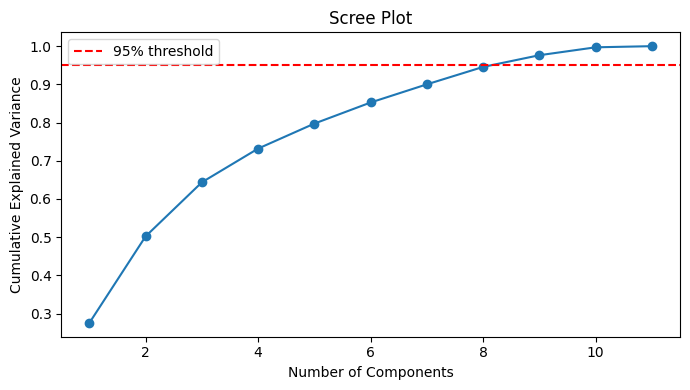

Components needed to explain 95% variance: 9


In [5]:
# Explained variance to choose number of components
pca_full = PCA()
pca_full.fit(X_scaled)

cumvar = np.cumsum(pca_full.explained_variance_ratio_)

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(cumvar)+1), cumvar, marker='o')
plt.axhline(0.95, color='red', linestyle='--', label='95% threshold')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Scree Plot')
plt.legend()
plt.tight_layout()
plt.show()

n_components = int(np.argmax(cumvar >= 0.95)) + 1
print(f'Components needed to explain 95% variance: {n_components}')

In [6]:
# Apply PCA with 2 components for visualisation
pca2 = PCA(n_components=2)
X_pca = pca2.fit_transform(X_scaled)

print(f'Variance explained by PC1+PC2: {pca2.explained_variance_ratio_.sum():.2%}')

Variance explained by PC1+PC2: 50.22%


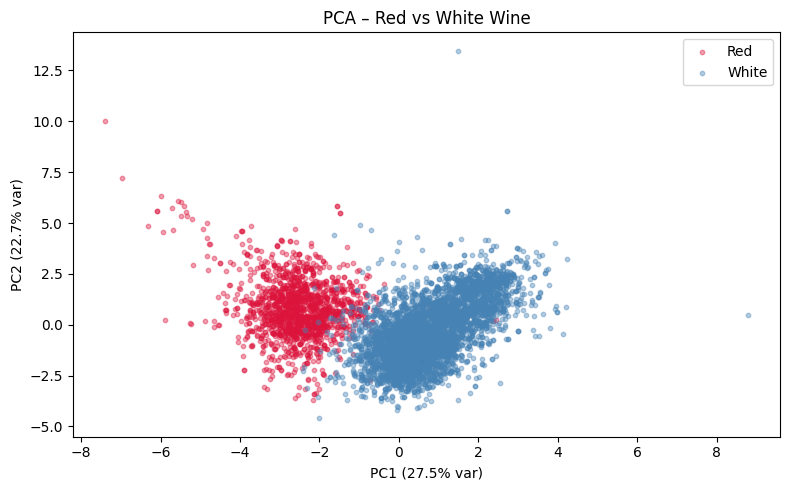

In [7]:
# Scatter plot: red vs white wine in PC space
colours = ['crimson', 'steelblue']
labels  = ['Red', 'White']

plt.figure(figsize=(8, 5))
for cls, col, lbl in zip([0, 1], colours, labels):
    mask = y == cls
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1],
                alpha=0.4, s=10, c=col, label=lbl)

plt.xlabel(f'PC1 ({pca2.explained_variance_ratio_[0]:.1%} var)')
plt.ylabel(f'PC2 ({pca2.explained_variance_ratio_[1]:.1%} var)')
plt.title('PCA – Red vs White Wine')
plt.legend()
plt.tight_layout()
plt.show()

In [8]:
# Feature loadings for PC1 and PC2
loadings = pd.DataFrame(pca2.components_.T,
                        index=features,
                        columns=['PC1', 'PC2'])

loadings.sort_values('PC1', ascending=False)

,PC1,PC2
total sulfur dioxide,0.487418,0.087266
free sulfur dioxide,0.430914,0.071933
residual sugar,0.345920,0.329914
citric acid,0.152388,0.183299
density,-0.044937,0.584037
alcohol,-0.106437,-0.465058
pH,-0.218686,-0.155869
fixed acidity,-0.238799,0.336355
chlorides,-0.290113,0.315258
sulphates,-0.294135,0.191716
